In [67]:
pip install emoji

  Obtaining dependency information for emoji from https://files.pythonhosted.org/packages/fd/8a/75e3177f374877b19dd3112820b071836ad1100f9f58424630b4783519bc/emoji-2.16.0-py3-none-any.whl.metadata
   ---------------------------------------- 0.0/610.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/610.9 kB ? eta -:--:--
    --------------------------------------- 10.2/610.9 kB ? eta -:--:--
    --------------------------------------- 10.2/610.9 kB ? eta -:--:--
   - ------------------------------------- 30.7/610.9 kB 220.2 kB/s eta 0:00:03
   --- ----------------------------------- 61.4/610.9 kB 273.8 kB/s eta 0:00:03
   ----- --------------------------------- 92.2/610.9 kB 375.8 kB/s eta 0:00:02
   ------- ------------------------------ 122.9/610.9 kB 425.1 kB/s eta 0:00:02
   -------------- ----------------------- 225.3/610.9 kB 655.6 kB/s eta 0:00:01
   --------------- ---------------------- 256.0/610.9 kB 716.5 kB/s eta 0:00:01
   ------------------------ ----------


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
pip install kagglehub

  Obtaining dependency information for kagglehub from https://files.pythonhosted.org/packages/0e/49/008002e0bf9bb4cfca85ce5e44314aef39f9a33dd15e31904d659ebca2d8/kagglehub-1.0.3-py3-none-any.whl.metadata
     ---------------------------------------- 0.0/40.4 kB ? eta -:--:--
     ---------- ----------------------------- 10.2/40.4 kB ? eta -:--:--
     ---------- ----------------------------- 10.2/40.4 kB ? eta -:--:--
     ---------------------------- --------- 30.7/40.4 kB 187.9 kB/s eta 0:00:01
     -------------------------------------- 40.4/40.4 kB 215.3 kB/s eta 0:00:00
  Obtaining dependency information for kagglesdk<1.0,>=0.1.38 from https://files.pythonhosted.org/packages/a6/36/706d494627f24e2d46e1b481a2641111454754b168b5c823442734d9f0cf/kagglesdk-0.1.38-py3-none-any.whl.metadata
   ---------------------------------------- 0.0/73.3 kB ? eta -:--:--
   ---------------------- ----------------- 41.0/73.3 kB 1.9 MB/s eta 0:00:01
   ---------------------------------------- 73.3/73.3 


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# libraries
import pandas as pd
import kagglehub
import os

e:\Projects\arabic-customer-intelligence\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Load the Arabic customer reviews dataset
# Download latest version
path = kagglehub.dataset_download("mohamedramadan2040/arabic-customer-reviews")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\User\.cache\kagglehub\datasets\mohamedramadan2040\arabic-customer-reviews\versions\2


In [4]:
source_file = os.path.join(path, 'Final_Data.csv')

df = pd.read_csv(source_file)

In [54]:
df.head()

,review_description,rating,company
0,رائع,positive,talbat
1,برنامج رائع جدا يساعد على تلبيه الاحتياجات بشك...,positive,talbat
2,التطبيق لا يغتح دائما بيعطيني لا يوجد اتصال با...,negative,talbat
3,لماذا لا يمكننا طلب من ماكدونالدز؟,negative,talbat
4,البرنامج بيظهر كل المطاعم و مغلقه مع انها بتكو...,negative,talbat


In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40046 entries, 0 to 40045
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   review_description  40045 non-null  str  
 1   rating              40046 non-null  str  
 2   company             40046 non-null  str  
dtypes: str(3)
memory usage: 5.0 MB


In [23]:
df.duplicated().sum()

np.int64(28)

In [28]:
print(df.describe(include='all'))


       review_description    rating company
count               40017     40017   40017
unique              39003         3      12
top                 ممتاز  positive  talbat
freq                   12     23897   32071


In [59]:
df['rating'].value_counts()

rating
positive    22787
negative    13753
neutral      1842
Name: count, dtype: int64

In [30]:
df['company'].value_counts()

company
talbat           32071
swvl              4685
telecom_egypt     2090
venus              281
Raya               268
TMG                233
elsewedy           147
hilton             100
capiter             73
Ezz Steel           47
nestle              18
domty                4
Name: count, dtype: int64

In [27]:
import re

# Function to check for Arabic characters
def has_no_arabic(text):
    return not bool(re.search('[\u0600-\u06FF]', str(text)))

non_arabic_rows = df[df['review_description'].apply(has_no_arabic)]

print(f"Number of rows with non-Arabic characters: {len(non_arabic_rows)}")
non_arabic_rows

Number of rows with non-Arabic characters: 1945


,review_description,rating,company
44,👎,negative,talbat
67,Wo 🙌🙌💋💋💋💋💋💋💙💙💙❤❤💖💖💖👍👍👍👌,positive,talbat
73,3w2d32d32,neutral,talbat
79,👍👏,positive,talbat
81,ugg,positive,talbat
...,...,...,...
39321,👌,positive,hilton
39369,I can't access my account please your help th...,positive,hilton
39375,❤️❤️❤️❤️,positive,domty
39430,👌👌💪,positive,elsewedy


In [46]:
social_df = df[df['review_description'].str.contains(r'@\w+|#\w+', na=False)]
social_df

,review_description,rating,company,cleaned_without_emoji,cleaned_with_emoji,cleaned_review_non_arabic
231,سيء جدا لانكم نصابين رجعو حقوق الموظفين #مقاطع...,negative,talbat,سيء جدا لانكم نصابين رجعو حقوق الموظفين #مقاطع...,سيء جدا لانكم نصابين رجعو حقوق الموظفين #مقاطع...,سيء جدا لانكم نصابين رجعو حقوق الموظفين #مقاطع...
289,شىكة نصب واحتيال ‏شركة طلبات في الأردن وعدت ال...,negative,talbat,شىكة نصب واحتيال ‏شركة طلبات في الأردن وعدت ال...,شىكة نصب واحتيال ‏شركة طلبات في الأردن وعدت ال...,شىكة نصب واحتيال ‏شركة طلبات في الأردن وعدت ال...
313,#قاطعوا تطبيق #طلبات ما تشاركوا بظلم الشباب ال...,negative,talbat,#قاطعوا تطبيق #طلبات ما تشاركوا بظلم الشباب ال...,#قاطعوا تطبيق #طلبات ما تشاركوا بظلم الشباب ال...,#قاطعوا تطبيق #طلبات ما تشاركوا بظلم الشباب ال...
331,#مقاطعة طلبات,negative,talbat,#مقاطعة طلبات,#مقاطعة طلبات,#مقاطعة طلبات
356,#إلغاء_تطبيق_طلبات موضفين طلبات مش عبيد عندكم,negative,talbat,#إلغاء_تطبيق_طلبات موضفين طلبات مش عبيد عندكم,#إلغاء_تطبيق_طلبات موضفين طلبات مش عبيد عندكم,#إلغاء_تطبيق_طلبات موضفين طلبات مش عبيد عندكم
...,...,...,...,...,...,...
38069,#انترنت_غير_محدود_في_مصر #انترنت_غير_محدود_في_...,positive,telecom_egypt,#انترنت_غير_محدود_في_مصر #انترنت_غير_محدود_في_...,#انترنت_غير_محدود_في_مصر #انترنت_غير_محدود_في_...,#انترنت_غير_محدود_في_مصر #انترنت_غير_محدود_في_...
38163,#انترنت_غير_محدود_في_مصر,negative,telecom_egypt,#انترنت_غير_محدود_في_مصر,#انترنت_غير_محدود_في_مصر,#انترنت_غير_محدود_في_مصر
38212,#انترنت_غير_محدود_فى_مصر,negative,telecom_egypt,#انترنت_غير_محدود_فى_مصر,#انترنت_غير_محدود_فى_مصر,#انترنت_غير_محدود_فى_مصر
39577,#كابيتر معاك في كل خطوة � …,positive,capiter,#كابيتر معاك في كل خطوة � …,#كابيتر معاك في كل خطوة � …,#كابيتر معاك في كل خطوة � …


In [47]:
elongated_df = df[df['review_description'].str.contains(r'(.)(?:\s?\1){2,}', na=False)]
elongated_df

C:\Users\User\AppData\Local\Temp\ipykernel_4836\1948446432.py:1: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  elongated_df = df[df['review_description'].str.contains(r'(.)(?:\s?\1){2,}', na=False)]


,review_description,rating,company,cleaned_without_emoji,cleaned_with_emoji,cleaned_review_non_arabic
6,جميل جدا رائع. . .,positive,talbat,جميل جدا رائع. . .,جميل جدا رائع. . .,جميل جدا رائع. . .
14,فاااااشل جدا البحث ما بعطي فائدة يتم كتابه إسم...,negative,talbat,فاااااشل جدا البحث ما بعطي فائدة يتم كتابه إسم...,فاااااشل جدا البحث ما بعطي فائدة يتم كتابه إسم...,فاااااشل جدا البحث ما بعطي فائدة يتم كتابه إسم...
22,راااائع,positive,talbat,راااائع,راااائع,راااائع
26,الحمدلله تم التواصل مع المسؤولين عن طلبات ورجع...,positive,talbat,الحمدلله تم التواصل مع المسؤولين عن طلبات ورجع...,الحمدلله تم التواصل مع المسؤولين عن طلبات ورجع...,الحمدلله تم التواصل مع المسؤولين عن طلبات ورجع...
36,ثثث3ثص22صصص,positive,talbat,ثثث3ثص22صصص,ثثث3ثص22صصص,ثثث3ثص22صصص
...,...,...,...,...,...,...
40022,الفكره ممتازة والتجربة جيده ولكن خدمة العملاء ...,neutral,swvl,الفكره ممتازة والتجربة جيده ولكن خدمة العملاء ...,الفكره ممتازة والتجربة جيده ولكن خدمة العملاء ...,الفكره ممتازة والتجربة جيده ولكن خدمة العملاء ...
40025,حجزت قبل كده من الهرم الي جامعه حلوان و لما رح...,negative,swvl,حجزت قبل كده من الهرم الي جامعه حلوان و لما رح...,حجزت قبل كده من الهرم الي جامعه حلوان و لما رح...,حجزت قبل كده من الهرم الي جامعه حلوان و لما رح...
40035,بعد ما اخدت الباقة الاولى ب ١٦٠ جنيه ٣٠ رحلة ب...,negative,swvl,بعد ما اخدت الباقة الاولى ب ١٦٠ جنيه ٣٠ رحلة ب...,بعد ما اخدت الباقة الاولى ب ١٦٠ جنيه ٣٠ رحلة ب...,بعد ما اخدت الباقة الاولى ب ١٦٠ جنيه ٣٠ رحلة ب...
40041,تجربه جيده بس ينقصها عدم اهتمام خدمة العملاء ب...,neutral,swvl,تجربه جيده بس ينقصها عدم اهتمام خدمة العملاء ب...,تجربه جيده بس ينقصها عدم اهتمام خدمة العملاء ب...,تجربه جيده بس ينقصها عدم اهتمام خدمة العملاء ب...


In [48]:
digits_df = df[df['review_description'].str.contains(r'\d{5,}', na=False)]
digits_df

,review_description,rating,company,cleaned_without_emoji,cleaned_with_emoji,cleaned_review_non_arabic
409,بطيئ وكثير من الاحيان يفصل اثناء الدفع ولا يوج...,negative,talbat,بطيئ وكثير من الاحيان يفصل اثناء الدفع ولا يوج...,بطيئ وكثير من الاحيان يفصل اثناء الدفع ولا يوج...,بطيئ وكثير من الاحيان يفصل اثناء الدفع ولا يوج...
457,بغنبيزديويوماةاع ة. اسمي خالة نتلى ‌ابءءء756665,positive,talbat,بغنبيزديويوماةاع ة. اسمي خالة نتلى ‌ابءءء756665,بغنبيزديويوماةاع ة. اسمي خالة نتلى ‌ابءءء756665,بغنبيزديويوماةاع ة. اسمي خالة نتلى ‌ابءءء756665
647,فى صزوصصى..١١١١٩ذ١٠٠ذ١ وةةى٩,positive,talbat,فى صزوصصى..١١١١٩ذ١٠٠ذ١ وةةى٩,فى صزوصصى..١١١١٩ذ١٠٠ذ١ وةةى٩,فى صزوصصى..١١١١٩ذ١٠٠ذ١ وةةى٩
2626,عندي قسائم وما بقدر استخدمها يرجى الاتصال بي ع...,negative,talbat,عندي قسائم وما بقدر استخدمها يرجى الاتصال بي ع...,عندي قسائم وما بقدر استخدمها يرجى الاتصال بي ع...,عندي قسائم وما بقدر استخدمها يرجى الاتصال بي ع...
2718,هواللةوالالةالحمد ٠١١٠٤١٤٢٩١٩,positive,talbat,هواللةوالالةالحمد ٠١١٠٤١٤٢٩١٩,هواللةوالالةالحمد ٠١١٠٤١٤٢٩١٩,هواللةوالالةالحمد ٠١١٠٤١٤٢٩١٩
...,...,...,...,...,...,...
37141,انا اخترت شاشه يونيون اير 50بوصه موديل معين ال...,negative,Raya,انا اخترت شاشه يونيون اير 50بوصه موديل معين ال...,انا اخترت شاشه يونيون اير 50بوصه موديل معين ال...,انا اخترت شاشه يونيون اير 50بوصه موديل معين ال...
37168,مفيش حد بيرد عليا في التليفون ١٩٩٠٠، ولا علي ا...,negative,Raya,مفيش حد بيرد عليا في التليفون ١٩٩٠٠، ولا علي ا...,مفيش حد بيرد عليا في التليفون ١٩٩٠٠، ولا علي ا...,مفيش حد بيرد عليا في التليفون ١٩٩٠٠، ولا علي ا...
37256,١٢٢٧١٢,negative,telecom_egypt,١٢٢٧١٢,١٢٢٧١٢,١٢٢٧١٢
38184,١٠٠١٠٠,positive,telecom_egypt,١٠٠١٠٠,١٠٠١٠٠,١٠٠١٠٠


In [49]:
tashkeel_df = df[df['review_description'].str.contains(r'[\u0617-\u061A\u064B-\u0652]', na=False)]
tashkeel_df

,review_description,rating,company,cleaned_without_emoji,cleaned_with_emoji,cleaned_review_non_arabic
5,أصبح غالي جداً,negative,talbat,أصبح غالي جداً,أصبح غالي جداً,أصبح غالي جداً
19,الضريبه عالية جداً,negative,talbat,الضريبه عالية جداً,الضريبه عالية جداً,الضريبه عالية جداً
60,تطبيق جداً جميل شكرا لجهودكم,positive,talbat,تطبيق جداً جميل شكرا لجهودكم,تطبيق جداً جميل شكرا لجهودكم,تطبيق جداً جميل شكرا لجهودكم
64,عذرا أيش الفائدة معظم المواقع يتعذر التوصيل له...,positive,talbat,عذرا أيش الفائدة معظم المواقع يتعذر التوصيل له...,عذرا أيش الفائدة معظم المواقع يتعذر التوصيل له...,عذرا أيش الفائدة معظم المواقع يتعذر التوصيل له...
65,سيء جداً,negative,talbat,سيء جداً,سيء جداً,سيء جداً
...,...,...,...,...,...,...
39991,أسوأ خدمة. كان السائق مبتذلاً ورفض فتح مكيف ال...,negative,swvl,أسوأ خدمة. كان السائق مبتذلاً ورفض فتح مكيف ال...,أسوأ خدمة. كان السائق مبتذلاً ورفض فتح مكيف ال...,أسوأ خدمة. كان السائق مبتذلاً ورفض فتح مكيف ال...
39992,أسوأ شركة وأسوأ مركز مساعدة ... لم يسمح السائق...,negative,swvl,أسوأ شركة وأسوأ مركز مساعدة ... لم يسمح السائق...,أسوأ شركة وأسوأ مركز مساعدة ... لم يسمح السائق...,أسوأ شركة وأسوأ مركز مساعدة ... لم يسمح السائق...
39994,ممتاز جدأً التزام جاد جداً شكراً\n,positive,swvl,ممتاز جدأً التزام جاد جداً شكراً\n,ممتاز جدأً التزام جاد جداً شكراً\n,ممتاز جدأً التزام جاد جداً شكراً\n
39996,خدمة رائعة ومريحة جداً وموفرة الوقت والمجهود و...,neutral,swvl,خدمة رائعة ومريحة جداً وموفرة الوقت والمجهود و...,خدمة رائعة ومريحة جداً وموفرة الوقت والمجهود و...,خدمة رائعة ومريحة جداً وموفرة الوقت والمجهود و...


In [51]:
punct_df = df[df['review_description'].str.contains(r"([!?. ]){2,}", na=False)]
punct_df

C:\Users\User\AppData\Local\Temp\ipykernel_4836\1235907054.py:1: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  punct_df = df[df['review_description'].str.contains(r"([!?. ]){2,}", na=False)]


,review_description,rating,company,cleaned_without_emoji,cleaned_with_emoji,cleaned_review_non_arabic
2,التطبيق لا يغتح دائما بيعطيني لا يوجد اتصال با...,negative,talbat,التطبيق لا يغتح دائما بيعطيني لا يوجد اتصال با...,التطبيق لا يغتح دائما بيعطيني لا يوجد اتصال با...,التطبيق لا يغتح دائما بيعطيني لا يوجد اتصال با...
6,جميل جدا رائع. . .,positive,talbat,جميل جدا رائع. . .,جميل جدا رائع. . .,جميل جدا رائع. . .
26,الحمدلله تم التواصل مع المسؤولين عن طلبات ورجع...,positive,talbat,الحمدلله تم التواصل مع المسؤولين عن طلبات ورجع...,الحمدلله تم التواصل مع المسؤولين عن طلبات ورجع...,الحمدلله تم التواصل مع المسؤولين عن طلبات ورجع...
27,شيء بخزي قعدت ساعه أستنى طلب واخر شيء كتبولي ط...,negative,talbat,شيء بخزي قعدت ساعه أستنى طلب واخر شيء كتبولي ط...,شيء بخزي قعدت ساعه أستنى طلب واخر شيء كتبولي ط...,شيء بخزي قعدت ساعه أستنى طلب واخر شيء كتبولي ط...
30,اصبح ادنى حد للطلب دينارين !!,negative,talbat,اصبح ادنى حد للطلب دينارين !!,اصبح ادنى حد للطلب دينارين !!,اصبح ادنى حد للطلب دينارين !!
...,...,...,...,...,...,...
40028,الابليكيشن يدخلنا فى متاهات لا نفهم منها شيء ....,negative,swvl,الابليكيشن يدخلنا فى متاهات لا نفهم منها شيء ....,الابليكيشن يدخلنا فى متاهات لا نفهم منها شيء ....,الابليكيشن يدخلنا فى متاهات لا نفهم منها شيء ....
40031,كل الخدمه ممتازه والكابتن كويس جدا . لكن انا ش...,neutral,swvl,كل الخدمه ممتازه والكابتن كويس جدا . لكن انا ش...,كل الخدمه ممتازه والكابتن كويس جدا . لكن انا ش...,كل الخدمه ممتازه والكابتن كويس جدا . لكن انا ش...
40035,بعد ما اخدت الباقة الاولى ب ١٦٠ جنيه ٣٠ رحلة ب...,negative,swvl,بعد ما اخدت الباقة الاولى ب ١٦٠ جنيه ٣٠ رحلة ب...,بعد ما اخدت الباقة الاولى ب ١٦٠ جنيه ٣٠ رحلة ب...,بعد ما اخدت الباقة الاولى ب ١٦٠ جنيه ٣٠ رحلة ب...
40041,تجربه جيده بس ينقصها عدم اهتمام خدمة العملاء ب...,neutral,swvl,تجربه جيده بس ينقصها عدم اهتمام خدمة العملاء ب...,تجربه جيده بس ينقصها عدم اهتمام خدمة العملاء ب...,تجربه جيده بس ينقصها عدم اهتمام خدمة العملاء ب...


## ***Data Cleaning***

In [5]:
# remove duplicates
df = df.drop_duplicates()

# remove rows with missing values
df = df.dropna()

# remove rows with neutral ratings
df = df[df['rating'] != 'neutral']

In [10]:
import re
import emoji
URL_RE             = re.compile(r'http\S+|www\S+|https\S+', flags=re.MULTILINE)
SOCIAL_RE          = re.compile(r'@\w+|#\w+')
REPEAT_PUNCT_RE    = re.compile(r"([!?. ,;:]){2,}")
ELONGATED_RE       = re.compile(r"(.)(?:\s*\1){2,}")
TASHKEEL_RE        = re.compile(r'[\u0617-\u061A\u064B-\u0652]')
WHITESPACE_RE      = re.compile(r'\s+')
WORD_REPETITION_RE = re.compile(r'\b(\w+)(?:\s+\1\b)+', re.IGNORECASE)

EMOJI_RE = re.compile(
    "["
    "\U0001F600-\U0001F64F"  
    "\U0001F300-\U0001F5FF"  
    "\U0001F680-\U0001F6FF"  
    "\U0001F1E0-\U0001F1FF"  
    "\u2702-\u27B0"
    "\u24C2-\u24FF"
    "]+", flags=re.UNICODE
)

EMOJI_TO_ARABIC = {
    "red_heart": "حب",
    "smiling_face_with_heart_eyes": "اعجاب",
    "thumbs_up": "ممتاز",
    "thumbs_down": "سيء",
    "fire": "رائع",
    "clapping_hands": "ممتاز",
    "crying_face": "زعلان",
    "angry_face": "غاضب",
    "enraged_face": "غاضب جداً",
    "face_with_tears_of_joy": "ضحك",
    "smiling_face": "سعيد",
    "broken_heart": "سيء",
    "cloud": "سحاب"
}

ARABIC_STOP_WORDS = {
    "في", "من", "على", "عن", "إلى", "البدء", "مع", "هذا", "هذه", "ذلك", 
    "التي", "الذي", "لان", "أن", "إن", "هو", "هي", "كان", "كانت", "ولا", 
    "وما", "به", "بها", "ففي", "وما", "منه", "لها", "فيه", "ال"
}


def normalize_arabic(text):
    """Normalize Arabic letters and remove Tashkeel for better text consistency."""
    if not isinstance(text, str):
        return ""
    text = re.sub(r"[إأآ]", "ا", text)
    text = re.sub(r"ى", "ي", text)
    text = re.sub(r"ة", "ه", text)
    text = TASHKEEL_RE.sub('', text)
    return text

def clean_non_arabic_but_keep_emojis(text):
    """Filter out non-Arabic text while keeping pure emoji or Arabic reviews."""
    if not isinstance(text, str):
        return ""
        
    text_without_emojis = EMOJI_RE.sub('', text)
    if re.search(r'[a-zA-Z]', text_without_emojis):
        return ""  
    has_arabic = bool(re.search('[\u0600-\u06FF]', text_without_emojis))
    has_only_emojis = (text_without_emojis.strip() == "" and bool(EMOJI_RE.search(text)))
    if has_arabic or has_only_emojis:
        return text  
    return ""

def clean_customer_review(text):
    """Full preprocessing pipeline: demojize emojis to Arabic terms, remove URLs/noise, normalize Arabic text, and drop stop words."""
    if not isinstance(text, str):
        return ""
    
    # 1. Convert emojis to English text codes (e.g., :red_heart:)
    text = emoji.demojize(text, language='en')
    
    # 2. Replace known emoji codes with Arabic descriptive words
    for eng_name, ar_name in EMOJI_TO_ARABIC.items():
        text = text.replace(f":{eng_name}:", f" {ar_name} ")
        
    # 3. Remove any remaining unmatched emoji tags or English symbols
    text = re.sub(r':[a-zA-Z_]+:', '', text)
    
    # 4. Convert text to lowercase
    text = text.lower()
    
    # 5. Remove URLs and social media handles
    text = URL_RE.sub('', text)
    text = SOCIAL_RE.sub('', text)
    
    # 6. Reduce elongated characters and repeated punctuations
    text = ELONGATED_RE.sub(r"\1\1", text)
    text = REPEAT_PUNCT_RE.sub(r"\1", text)
    
    # 7. Apply Arabic normalization
    text = normalize_arabic(text)
    
    # 8. Remove Arabic stop words and short meaningless tokens
    words = text.split()
    filtered_words = [w for w in words if w not in ARABIC_STOP_WORDS and len(w) > 1]
    text = " ".join(filtered_words)
    
    # 9. Remove consecutive redundant words
    text = WORD_REPETITION_RE.sub(r'\1', text)
    
    # 10. Clean up extra whitespaces
    text = WHITESPACE_RE.sub(' ', text).strip()
    
    return text

# --- Pipeline Execution ---
df['filtered_review'] = df['review_description'].apply(clean_non_arabic_but_keep_emojis)
df = df[df['filtered_review'].str.strip() != ""].copy()
df['cleaned_review_description'] = df['filtered_review'].apply(clean_customer_review)

display(df.head(5))

,review_description,rating,company,filtered_review,cleaned_review_description
0,رائع,1,talbat,رائع,رائع
1,برنامج رائع جدا يساعد على تلبيه الاحتياجات بشك...,1,talbat,برنامج رائع جدا يساعد على تلبيه الاحتياجات بشك...,برنامج رائع جدا يساعد علي تلبيه الاحتياجات بشك...
2,التطبيق لا يغتح دائما بيعطيني لا يوجد اتصال با...,0,talbat,التطبيق لا يغتح دائما بيعطيني لا يوجد اتصال با...,التطبيق لا يغتح دائما بيعطيني لا يوجد اتصال با...
3,لماذا لا يمكننا طلب من ماكدونالدز؟,0,talbat,لماذا لا يمكننا طلب من ماكدونالدز؟,لماذا لا يمكننا طلب ماكدونالدز؟
4,البرنامج بيظهر كل المطاعم و مغلقه مع انها بتكو...,0,talbat,البرنامج بيظهر كل المطاعم و مغلقه مع انها بتكو...,البرنامج بيظهر كل المطاعم مغلقه انها بتكون فات...


In [7]:
# 1. Map text labels to numeric values (Positive: 1, Negative: 0)
df['rating'] = df['rating'].map({'positive': 1, 'negative': 0})

## ***Modling***

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X = tfidf.fit_transform(df['cleaned_review_description'])
y = df['rating']

In [12]:
from sklearn.model_selection import train_test_split

# Split data into Training set (80%) and Temporary Test/Validation set (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)


In [13]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    C=1.0
)
model.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

In [14]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.86      0.85      2743
           1       0.92      0.90      0.91      4508

    accuracy                           0.89      7251
   macro avg       0.88      0.88      0.88      7251
weighted avg       0.89      0.89      0.89      7251



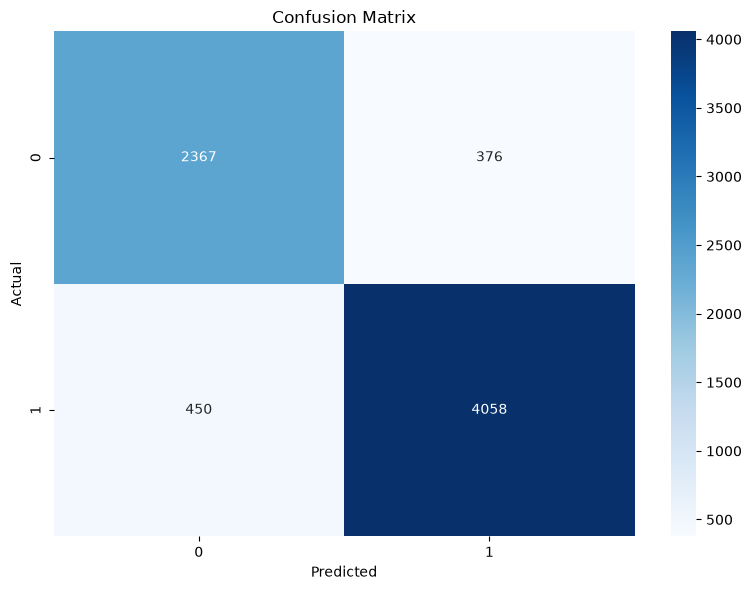

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=model.classes_,
            yticklabels=model.classes_)
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

## ***Semantic Topic Modeling***

In [102]:
pip install bertopic sentence-transformers

  Obtaining dependency information for bertopic from https://files.pythonhosted.org/packages/81/d2/2eb2fec18b3d2cf487d5d1d9b484c6483c7f0f1a3c6f64e2bb9cb7972a3f/bertopic-0.17.4-py3-none-any.whl.metadata
  Obtaining dependency information for sentence-transformers from https://files.pythonhosted.org/packages/66/ae/aac4fcaf7aa27daee96aa15d74770b38bb5ff50b1d31ccf12becd68c6e8b/sentence_transformers-6.2.0-py3-none-any.whl.metadata
  Obtaining dependency information for hdbscan>=0.8.29 from https://files.pythonhosted.org/packages/b5/a2/959f617dbff9ebe0ef9b55f61c84b7ad00e5eb91b47b838b3a1a2bf0aa95/hdbscan-0.8.44-cp312-cp312-win_amd64.whl.metadata
  Obtaining dependency information for umap-learn>=0.5.0 from https://files.pythonhosted.org/packages/1b/98/f63318ccbe75c810011fe9233884c5d348d94d90005de1b79e5f93bef9c0/umap_learn-0.5.12-py3-none-any.whl.metadata
  Obtaining dependency information for plotly>=4.7.0 from https://files.pythonhosted.org/packages/e5/7d/905a3a3d51087515719058c94cfbda2ff0fc1


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP
import pandas as pd
import random

#1. Initialize the embedding model
embedding_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

# 2. Initialize the UMAP model
umap_model = UMAP(
    n_neighbors=15,
    n_components=5,
    min_dist=0.0,
    metric='cosine',
    low_memory=True
)

# 3. Vectorizer model for extracting n-grams
vectorizer_model = CountVectorizer(ngram_range=(1, 2), min_df=1)

# 4. Initialize BERTopic model
topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    vectorizer_model=vectorizer_model,
    language="arabic",       
    calculate_probabilities=False,
    verbose=True
)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2457.78it/s]


In [17]:
import random

all_companies_topics = {}

for target_company in df['company'].unique():
    company_docs = df[df['company'] == target_company]['cleaned_review_description'].tolist()
    
    if len(company_docs) > 2000:
        company_docs = random.sample(company_docs, 2000)
        
    if len(company_docs) > 10:
        print(f"--- Processing company: {target_company} ({len(company_docs)} reviews) ---")
        
        topics, probs = topic_model.fit_transform(company_docs)
        
        all_companies_topics[target_company] = topic_model.get_topic_info()
    else:
        print(f"Skipping {target_company} (too few reviews).")


2026-11-02 00:48:13,175 - BERTopic - Embedding - Transforming documents to embeddings.


--- Processing company: talbat (2000 reviews) ---


Batches: 100%|██████████| 63/63 [00:17<00:00,  3.55it/s]
2026-11-02 00:48:30,935 - BERTopic - Embedding - Completed ✓
2026-11-02 00:48:30,938 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-02 00:49:07,617 - BERTopic - Dimensionality - Completed ✓
2026-11-02 00:49:07,638 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-02 00:49:07,793 - BERTopic - Cluster - Completed ✓
2026-11-02 00:49:07,831 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-02 00:49:08,018 - BERTopic - Representation - Completed ✓
2026-11-02 00:49:08,272 - BERTopic - Embedding - Transforming documents to embeddings.


--- Processing company: swvl (2000 reviews) ---


Batches: 100%|██████████| 63/63 [00:20<00:00,  3.10it/s]
2026-11-02 00:49:28,601 - BERTopic - Embedding - Completed ✓
2026-11-02 00:49:28,603 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-02 00:49:36,935 - BERTopic - Dimensionality - Completed ✓
2026-11-02 00:49:36,937 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-02 00:49:37,054 - BERTopic - Cluster - Completed ✓
2026-11-02 00:49:37,061 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-02 00:49:37,245 - BERTopic - Representation - Completed ✓
2026-11-02 00:49:37,498 - BERTopic - Embedding - Transforming documents to embeddings.


--- Processing company: venus (263 reviews) ---


... (13 outputs left out)

--- Processing company: TMG (215 reviews) ---


Batches: 100%|██████████| 7/7 [00:03<00:00,  2.25it/s]
2026-11-02 00:50:17,404 - BERTopic - Embedding - Completed ✓
2026-11-02 00:50:17,406 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-02 00:50:17,704 - BERTopic - Dimensionality - Completed ✓
2026-11-02 00:50:17,706 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-02 00:50:17,723 - BERTopic - Cluster - Completed ✓
2026-11-02 00:50:17,730 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-02 00:50:17,787 - BERTopic - Representation - Completed ✓
2026-11-02 00:50:17,857 - BERTopic - Embedding - Transforming documents to embeddings.


--- Processing company: Ezz Steel (40 reviews) ---


Batches: 100%|██████████| 2/2 [00:00<00:00,  2.22it/s]
2026-11-02 00:50:18,771 - BERTopic - Embedding - Completed ✓
2026-11-02 00:50:18,772 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-02 00:50:18,876 - BERTopic - Dimensionality - Completed ✓
2026-11-02 00:50:18,878 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-02 00:50:18,888 - BERTopic - Cluster - Completed ✓
2026-11-02 00:50:18,894 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-02 00:50:18,910 - BERTopic - Representation - Completed ✓


In [18]:
import os
import pickle

os.makedirs('../models', exist_ok=True)

# 1. Save the trained Logistic Regression model
with open('../models/logistic_model.pkl', 'wb') as f:
    pickle.dump(model, f)

# 2. Save the fitted TF-IDF Vectorizer
with open('../models/tfidf_vectorizer.pkl', 'wb') as f:
    pickle.dump(tfidf, f)

# 3. Save the companies topics dictionary
with open('../models/companies_topics.pkl', 'wb') as f:
    pickle.dump(all_companies_topics, f)

print("✅ All models and topics successfully saved in the main project directory!")

✅ All models and topics successfully saved in the main project directory!
